In [1]:
import numpy as np
import pandas as pd
from pathlib import Path # 
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


In [2]:
data_root = Path("datapack")
if not data_root.exists():
    data_root = Path("..") / "datapack"
print("Datapack path:", data_root)

Datapack path: datapack


In [3]:

def _read_table_file(path):
    suffixes = path.suffixes
    if suffixes[-2:] == [".jsonl", ".gz"]:
        return pd.read_json(path, compression="gzip", lines=True)
    try:
        return pd.read_csv(path, compression="infer", encoding="utf-8")
    except UnicodeDecodeError:
        return pd.read_csv(path, compression="infer", encoding="cp1252")


def _table_name(folder, path):
    stem = path.name.removesuffix(".gz").removesuffix(".csv").removesuffix(".jsonl")
    if folder == "bookings":
        return path.relative_to(data_root / folder).parts[0]
    if folder == "results":
        return "results"
    return stem

In [4]:

def load_datapack(root=data_root):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(
            f"Datapack folder not found: {root.resolve()}. "
            "Check DATA_ROOT and keep the folder name 'datapack'."
        )

    supported = ("*.csv", "*.csv.gz", "*.jsonl.gz")
    needed_folders = {"bookings", "results", "plan"}
    paths = sorted(
        path for pattern in supported for path in root.rglob(pattern)
        if path.relative_to(root).parts[0] in needed_folders
    )
    grouped_frames = {}

    for path in paths:
        relative_path = path.relative_to(root)
        folder = relative_path.parts[0]
        table = _table_name(folder, path)
        frame = _read_table_file(path)
        frame["source_file"] = path.name
        frame["source_path"] = relative_path.as_posix()
        grouped_frames.setdefault((folder, table), []).append(frame)

    if not grouped_frames:
        raise FileNotFoundError(f"No supported data files found under {root.resolve()}")

    data = {}
    for (folder, table), frames in grouped_frames.items():
        data.setdefault(folder, {})[table] = pd.concat(frames, ignore_index=True, sort=False)

    return data

In [5]:

data = load_datapack()
bookings_data = data["bookings"]

print("Loaded tables:")
for folder, tables in data.items():
    for table, frame in tables.items():
        print(f"{folder}/{table}: {len(frame):,} rows, {len(frame.columns)} columns")

Loaded tables:
bookings/legacy: 1,252,786 rows, 14 columns
bookings/nova: 26,543 rows, 14 columns
plan/plan_2026_H1: 6 rows, 10 columns
results/results: 1,078,420 rows, 7 columns


In [6]:
legacy = data["bookings"]["legacy"].copy()
nova = data["bookings"]["nova"].copy()

raw_legacy = len(legacy)
raw_nova = len(nova)

print("Raw Legacy rows:", f"{raw_legacy:,}")
print("Raw Nova bookings:", f"{raw_nova:,}")

Raw Legacy rows: 1,252,786
Raw Nova bookings: 26,543


In [7]:
before = len(legacy)
legacy = legacy.loc[legacy["city"].astype("string").str.strip().ne("city")].copy()
header_rows = before - len(legacy)

print(f"Removed {header_rows:,} repeated header rows")

Removed 21 repeated header rows


In [8]:
for col in ["created_at", "slot_at"]:
    legacy[col] = pd.to_datetime(
        legacy[col],
        format="%d/%m/%Y %H:%M",
        errors="coerce")

legacy["booking_id"] = legacy["booking_id"].astype("string").str.strip()
for col in ["city", "clinic_id", "channel", "source", "patient_id", "test_code"]:
    if col in legacy.columns:
        legacy[col] = legacy[col].astype("string").str.strip()

legacy["city"] = legacy["city"].replace({"Bangalore": "Bengaluru"})
for col in ["channel", "source"]:
    legacy[col] = legacy[col].str.lower()

for col in ["test_price", "home_fee"]:
    legacy[col] = pd.to_numeric(legacy[col], errors="coerce")

print("Legacy missing dates:")
display(legacy[["created_at", "slot_at"]].isna().sum())
print("Legacy duplicate full rows:", legacy.duplicated().sum())

Legacy missing dates:


created_at    0
slot_at       0
dtype: int64

Legacy duplicate full rows: 0


In [9]:

def get_patient_id(value):
    if isinstance(value, dict):
        return value.get("patient_id", pd.NA)
    return pd.NA


nova["patient_id"] = nova["patient"].apply(get_patient_id)

nova = nova.explode("tests", ignore_index=True)

def get_test_code(value):
    if isinstance(value, dict):
        return value.get("code", pd.NA)
    return pd.NA


def get_test_price(value):
    if isinstance(value, dict):
        return value.get("price", pd.NA)
    return pd.NA


nova["test_code"] = nova["tests"].apply(get_test_code)
nova["test_price"] = nova["tests"].apply(get_test_price)

In [10]:

for col in ["booking_id", "city", "clinic_id", "channel", "source", "patient_id", "test_code", "rescheduled_from", "status_at_export"]:
    if col in nova.columns:
        nova[col] = nova[col].astype("string").str.strip()

nova["city"] = nova["city"].replace({"Bangalore": "Bengaluru"})
for col in ["channel", "source", "status_at_export"]:
    if col in nova.columns:
        nova[col] = nova[col].str.lower()

In [11]:

for col in ["created_at", "slot_at"]:
    nova[col] = (
        pd.to_datetime(nova[col], errors="coerce", utc=True)
        .dt.tz_convert("Asia/Kolkata")
        .dt.tz_localize(None)
    )

for col in ["test_price", "home_fee"]:
    if col in nova.columns:
        nova[col] = pd.to_numeric(nova[col], errors="coerce")

print(f"Nova rows after exploding tests: {len(nova):,}")
print("Nova missing dates:")
display(nova[["created_at", "slot_at"]].isna().sum())

Nova rows after exploding tests: 62,439
Nova missing dates:


created_at    0
slot_at       0
dtype: int64

In [12]:

common_columns = [
    "booking_id", "created_at", "slot_at", "city", "clinic_id",
    "channel", "patient_id", "test_code", "test_price", "home_fee",
    "rescheduled_from", "status_at_export", "source_file", "source_path", "source"
]

legacy["booking_system"] = "legacy"
nova["booking_system"] = "nova"

bookings_raw = pd.concat(
    [
        legacy.reindex(columns=common_columns + ["booking_system"]),
        nova.reindex(columns=common_columns + ["booking_system"])
    ],
    ignore_index=True)

n_raw_booking_test_rows = len(bookings_raw)

In [13]:

for col in ["booking_id", "city", "clinic_id", "channel", "patient_id", "test_code", "source"]:
    bookings_raw[col] = bookings_raw[col].astype("string").str.strip()

bookings_raw["city"] = bookings_raw["city"].replace({"Bangalore": "Bengaluru"})
for col in ["channel", "source"]:
    bookings_raw[col] = bookings_raw[col].str.lower()

for col in ["test_price", "home_fee"]:
    bookings_raw[col] = pd.to_numeric(bookings_raw[col], errors="coerce")

print(f"Combined raw booking-test rows: {n_raw_booking_test_rows:,}")
display(bookings_raw.head())

Combined raw booking-test rows: 1,315,204


,booking_id,created_at,slot_at,city,clinic_id,channel,patient_id,test_code,test_price,home_fee,rescheduled_from,status_at_export,source_file,source_path,source,booking_system
0,BK-AHM-202501-000001,2025-01-08 03:16:00,2025-01-09 08:26:00,Ahmedabad,AHM-03,clinic,PAHM0028525,T009,800.0,0,NaN,NaN,bookings_2025-01.csv.gz,bookings/legacy/ahmedabad/bookings_2025-01.csv.gz,walkin,legacy
1,BK-AHM-202501-000001,2025-01-08 03:16:00,2025-01-09 08:26:00,Ahmedabad,AHM-03,clinic,PAHM0028525,T004,650.0,0,NaN,NaN,bookings_2025-01.csv.gz,bookings/legacy/ahmedabad/bookings_2025-01.csv.gz,walkin,legacy
2,BK-AHM-202501-000001,2025-01-08 03:16:00,2025-01-09 08:26:00,Ahmedabad,AHM-03,clinic,PAHM0028525,T007,550.0,0,NaN,NaN,bookings_2025-01.csv.gz,bookings/legacy/ahmedabad/bookings_2025-01.csv.gz,walkin,legacy
3,BK-AHM-202501-000002,2025-01-03 05:18:00,2025-01-06 13:22:00,Ahmedabad,AHM-04,clinic,PAHM0031384,T004,650.0,0,NaN,NaN,bookings_2025-01.csv.gz,bookings/legacy/ahmedabad/bookings_2025-01.csv.gz,app,legacy
4,BK-AHM-202501-000003,2025-01-27 10:46:00,2025-01-28 13:37:00,Ahmedabad,AHM-01,home,PAHM0027001,T003,450.0,150,NaN,NaN,bookings_2025-01.csv.gz,bookings/legacy/ahmedabad/bookings_2025-01.csv.gz,app,legacy


In [14]:

rejects = []
remaining = bookings_raw.copy()

def reject_rows(frame, mask, reason):
    mask = mask.fillna(True)
    rejected_part = frame.loc[mask].copy()
    rejected_part["reason"] = reason
    rejects.append(rejected_part)
    accepted_part = frame.loc[~mask].copy()
    print(f"{reason}: {len(rejected_part):,}")
    return accepted_part

In [15]:

remaining = reject_rows(
    remaining,
    remaining["booking_id"].isna() | remaining["booking_id"].eq(""),
    "missing booking_id")
remaining = reject_rows(
    remaining,
    remaining["created_at"].isna() | remaining["slot_at"].isna(),
    "missing or invalid created_at/slot_at")

test_code_valid = remaining["test_code"].str.match(r"^(T\d{3}|PK\d{2})$", na=False)
remaining = reject_rows(
    remaining,
    ~test_code_valid,
    "missing or invalid test_code")
remaining = reject_rows(
    remaining,
    remaining["slot_at"] < remaining["created_at"],
    "slot_at before created_at")

allowed_channels = ["clinic", "home"]
allowed_sources = ["app", "phone", "walkin"]

bad_channel = ~remaining["channel"].isin(allowed_channels)
bad_source = ~remaining["source"].isin(allowed_sources)
remaining = reject_rows(
    remaining,
    bad_channel | bad_source,
    "channel/source missing or outside allowed values")

missing booking_id: 0
missing or invalid created_at/slot_at: 0
missing or invalid test_code: 1,311
slot_at before created_at: 2,442
channel/source missing or outside allowed values: 0


In [16]:

accepted = remaining.copy()

if len(rejects) > 0:
    rejects_df = pd.concat(rejects, ignore_index=True)
else:
    rejects_df = bookings_raw.iloc[0:0].copy()
    rejects_df["reason"] = pd.Series(dtype="string")

print()
print(f"Original rows: {n_raw_booking_test_rows:,}")
print(f"Accepted rows: {len(accepted):,}")
print(f"Rejected rows: {len(rejects_df):,}")
print(f"Accepted + rejected: {len(accepted) + len(rejects_df):,}")

assert n_raw_booking_test_rows == len(accepted) + len(rejects_df)

rejects_df.to_csv("rejects_bookings.csv", index=False)
print("Saved rejects_bookings.csv")


Original rows: 1,315,204
Accepted rows: 1,311,451
Rejected rows: 3,753
Accepted + rejected: 1,315,204
Saved rejects_bookings.csv


In [17]:
print("Missing values in key columns:")
display(accepted[["booking_id", "created_at", "slot_at", "city", "channel", "patient_id", "test_code"]].isna().sum())

print("Accepted rows by booking system:")
display(accepted["booking_system"].value_counts(dropna=False))

print("Accepted rows by city:")
display(accepted["city"].value_counts(dropna=False))

Missing values in key columns:


booking_id    0
created_at    0
slot_at       0
city          0
channel       0
patient_id    0
test_code     0
dtype: int64

Accepted rows by booking system:


booking_system
legacy    1249033
nova        62418
Name: count, dtype: int64

Accepted rows by city:


city
Bengaluru    300311
Chennai      242933
Ahmedabad    234690
Hyderabad    220380
Pune         184559
Jaipur       128578
Name: count, dtype: Int64

In [18]:

if not accepted.columns.is_unique:
    duplicate_columns = accepted.columns[accepted.columns.duplicated()].tolist()
    raise ValueError(f"Duplicate column names before booking aggregation: {duplicate_columns}")

for date_col in ["created_at", "slot_at"]:
    accepted[date_col] = pd.to_datetime(accepted[date_col], errors="coerce")

accepted["has_package_row"] = accepted["test_code"].str.startswith("PK", na=False)

bookings = (
    accepted.groupby("booking_id", as_index=False)
    .agg(
        n_tests=("test_code", "count"),
        price_sum=("test_price", "sum"),
        home_fee=("home_fee", "first"),
        has_package=("has_package_row", "any"),
        created_at=("created_at", "first"),
        slot_at=("slot_at", "first"),
        city=("city", "first"),
        clinic_id=("clinic_id", "first"),
        channel=("channel", "first"),
        source=("source", "first"),
        patient_id=("patient_id", "first"),
        rescheduled_from=("rescheduled_from", "first"),
        status_at_export=("status_at_export", "first"),
        booking_system=("booking_system", "first")))

In [19]:
# Add booking-level columns: amount, month, reschedule flags.
bookings["home_fee"] = pd.to_numeric(bookings["home_fee"], errors="coerce").fillna(0)
bookings["price_sum"] = pd.to_numeric(bookings["price_sum"], errors="coerce").fillna(0)
bookings["amount_rs"] = bookings["price_sum"] + bookings["home_fee"]
bookings["month"] = bookings["slot_at"].dt.to_period("M").astype("string")
bookings["is_reschedule"] = bookings["rescheduled_from"].notna()

bookings["is_superseded"] = (
    bookings["status_at_export"].astype("string").str.lower().eq("rescheduled")
    .fillna(False)
)

print(f"Booking-level rows: {len(bookings):,}")
print(f"Test count across accepted booking-test rows: {int(bookings['n_tests'].sum()):,}")
display(bookings.head())

Booking-level rows: 566,792
Test count across accepted booking-test rows: 1,311,451


,booking_id,n_tests,price_sum,home_fee,has_package,created_at,slot_at,city,clinic_id,channel,source,patient_id,rescheduled_from,status_at_export,booking_system,amount_rs,month,is_reschedule,is_superseded
0,BK-AHM-202501-000001,3,2000.0,0,False,2025-01-08 03:16:00,2025-01-09 08:26:00,Ahmedabad,AHM-03,clinic,walkin,PAHM0028525,None,None,legacy,2000.0,2025-01,False,False
1,BK-AHM-202501-000002,1,650.0,0,False,2025-01-03 05:18:00,2025-01-06 13:22:00,Ahmedabad,AHM-04,clinic,app,PAHM0031384,None,None,legacy,650.0,2025-01,False,False
2,BK-AHM-202501-000003,4,1670.0,150,False,2025-01-27 10:46:00,2025-01-28 13:37:00,Ahmedabad,AHM-01,home,app,PAHM0027001,None,None,legacy,1820.0,2025-01,False,False
3,BK-AHM-202501-000004,1,160.0,0,False,2025-01-20 02:48:00,2025-01-24 07:15:00,Ahmedabad,AHM-03,clinic,app,PAHM0007069,None,None,legacy,160.0,2025-01,False,False
4,BK-AHM-202501-000005,2,1900.0,0,False,2025-01-06 08:21:00,2025-01-11 09:56:00,Ahmedabad,AHM-03,clinic,app,PAHM0002520,None,None,legacy,1900.0,2025-01,False,False


In [20]:

booking_consistency = (
    accepted.groupby("booking_id", as_index=False)
    .agg(
        city_values=("city", "nunique"),
        channel_values=("channel", "nunique"),
        patient_values=("patient_id", "nunique"),
        slot_values=("slot_at", "nunique")
    )
)

print("Bookings with more than one city:", int((booking_consistency["city_values"] > 1).sum()))
print("Bookings with more than one channel:", int((booking_consistency["channel_values"] > 1).sum()))
print("Bookings with more than one patient:", int((booking_consistency["patient_values"] > 1).sum()))
print("Bookings with more than one slot:", int((booking_consistency["slot_values"] > 1).sum()))

display(booking_consistency.loc[
    (booking_consistency["city_values"] > 1) |
    (booking_consistency["channel_values"] > 1) |
    (booking_consistency["patient_values"] > 1) |
    (booking_consistency["slot_values"] > 1)
].head(20))

Bookings with more than one city: 0
Bookings with more than one channel: 0
Bookings with more than one patient: 0
Bookings with more than one slot: 0


,booking_id,city_values,channel_values,patient_values,slot_values


In [21]:
results = data["results"]["results"].copy()
plan = data["plan"]["plan_2026_H1"].copy()

for table_name, frame in [("results", results), ("plan_2026_H1", plan)]:
    print(f"\n{table_name}: {frame.shape}")
    print(frame.columns.tolist())



results: (1078420, 7)
['booking_id', 'test_code', 'result_ts', 'result_value', 'result_flag', 'source_file', 'source_path']

plan_2026_H1: (6, 10)
['city', 'metric', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', 'source_file', 'source_path']


In [22]:
print(bookings.columns.tolist())

['booking_id', 'n_tests', 'price_sum', 'home_fee', 'has_package', 'created_at', 'slot_at', 'city', 'clinic_id', 'channel', 'source', 'patient_id', 'rescheduled_from', 'status_at_export', 'booking_system', 'amount_rs', 'month', 'is_reschedule', 'is_superseded']


In [23]:
display(bookings.head())

,booking_id,n_tests,price_sum,home_fee,has_package,created_at,slot_at,city,clinic_id,channel,source,patient_id,rescheduled_from,status_at_export,booking_system,amount_rs,month,is_reschedule,is_superseded
0,BK-AHM-202501-000001,3,2000.0,0,False,2025-01-08 03:16:00,2025-01-09 08:26:00,Ahmedabad,AHM-03,clinic,walkin,PAHM0028525,None,None,legacy,2000.0,2025-01,False,False
1,BK-AHM-202501-000002,1,650.0,0,False,2025-01-03 05:18:00,2025-01-06 13:22:00,Ahmedabad,AHM-04,clinic,app,PAHM0031384,None,None,legacy,650.0,2025-01,False,False
2,BK-AHM-202501-000003,4,1670.0,150,False,2025-01-27 10:46:00,2025-01-28 13:37:00,Ahmedabad,AHM-01,home,app,PAHM0027001,None,None,legacy,1820.0,2025-01,False,False
3,BK-AHM-202501-000004,1,160.0,0,False,2025-01-20 02:48:00,2025-01-24 07:15:00,Ahmedabad,AHM-03,clinic,app,PAHM0007069,None,None,legacy,160.0,2025-01,False,False
4,BK-AHM-202501-000005,2,1900.0,0,False,2025-01-06 08:21:00,2025-01-11 09:56:00,Ahmedabad,AHM-03,clinic,app,PAHM0002520,None,None,legacy,1900.0,2025-01,False,False


In [24]:
start_25 = pd.Timestamp("2025-01-01")
start_26 = pd.Timestamp("2026-01-01")
end_25 = pd.Timestamp("2025-07-01")
end_26 = pd.Timestamp("2026-07-01")

current_bookings = bookings.loc[~bookings["is_superseded"]].copy()


jan_jun_25 = current_bookings.loc[
    (current_bookings["slot_at"] >= start_25) &
    (current_bookings["slot_at"] < end_25)
].copy()

jan_jun_26 = current_bookings.loc[
    (current_bookings["slot_at"] >= start_26) &
    (current_bookings["slot_at"] < end_26)
].copy()

In [62]:
tests_25 = jan_jun_25["n_tests"].sum()
tests_26 = jan_jun_26["n_tests"].sum()

if tests_25 > 0:
    growth_pct = (tests_26 - tests_25) / tests_25 * 100
else:
    growth_pct = np.nan

print("Jan-Jun 2025 booking-based test volume:", f"{tests_25:,.0f}")
print("Jan-Jun 2026 booking-based test volume:", f"{tests_26:,.0f}")
print(f"Booking-based growth: {growth_pct:.2f}%")
print("Plan growth:", "18%")
print(f"Gap versus plan: {18 - growth_pct:.2f} percentage points")

Jan-Jun 2025 booking-based test volume: 435,008
Jan-Jun 2026 booking-based test volume: 456,788
Booking-based growth: 5.01%
Plan growth: 18%
Gap versus plan: 12.99 percentage points


In [63]:
reject_audit = rejects_df.copy()
for date_col in ["created_at", "slot_at"]:
    reject_audit[date_col] = pd.to_datetime(reject_audit[date_col], errors="coerce")

in_h1_25 = (reject_audit["slot_at"] >= start_25) & (reject_audit["slot_at"] < end_25)
in_h1_26 = (reject_audit["slot_at"] >= start_26) & (reject_audit["slot_at"] < end_26)
is_slot_reject = reject_audit["reason"].eq("slot_at before created_at")
is_code_reject = reject_audit["reason"].eq("missing or invalid test_code")

slot_rejects_25 = reject_audit.loc[is_slot_reject & in_h1_25]
slot_rejects_26 = reject_audit.loc[is_slot_reject & in_h1_26]
missing_code_rows_25 = reject_audit.loc[is_code_reject & in_h1_25]
missing_code_rows_26 = reject_audit.loc[is_code_reject & in_h1_26]

growth_if_temporal_rejects_kept = ((tests_26 + len(slot_rejects_26)) / (tests_25 + len(slot_rejects_25)) - 1) * 100
growth_if_missing_codes_assumed_tests = ((tests_26 + len(missing_code_rows_26)) / (tests_25 + len(missing_code_rows_25)) - 1) * 100

print(f"A headline with temporal rejects excluded: {growth_pct:.2f}%")
print(f"A sensitivity if temporal-reject rows were counted as tests: {growth_if_temporal_rejects_kept:.2f}%")
print(f"Missing/invalid-code rows by H1: 2025={len(missing_code_rows_25):,}; 2026={len(missing_code_rows_26):,}; not counted as confirmed tests")
print(f"Affected booking IDs by H1: 2025={missing_code_rows_25['booking_id'].nunique():,}; 2026={missing_code_rows_26['booking_id'].nunique():,}")
print(f"A headline if missing-code rows were each assumed to be one test (sensitivity only): {growth_if_missing_codes_assumed_tests:.2f}%")

A headline with temporal rejects excluded: 5.01%
A sensitivity if temporal-reject rows were counted as tests: 4.97%
Missing/invalid-code rows by H1: 2025=422; 2026=464; not counted as confirmed tests
Affected booking IDs by H1: 2025=422; 2026=463
A headline if missing-code rows were each assumed to be one test (sensitivity only): 5.01%


In [64]:
growth_check = pd.DataFrame({
    "measure": ["Booking-based test volume"],
    "Jan-Jun 2025": [tests_25],
    "Jan-Jun 2026": [tests_26],
    "change_in_tests": [tests_26 - tests_25],
    "growth_pct": [growth_pct]
})

display(growth_check)

if growth_pct >= 0:
    print(f"Test volume increased by {growth_pct:.2f}%; this is growth, not a drop.")
else:
    print(f"Test volume decreased by {abs(growth_pct):.2f}%.")


,measure,Jan-Jun 2025,Jan-Jun 2026,change_in_tests,growth_pct
0,Booking-based test volume,435008,456788,21780,5.006804


Test volume increased by 5.01%; this is growth, not a drop.


In [65]:
all_jan_jun_25 = bookings.loc[
    (bookings["slot_at"] >= start_25) &
    (bookings["slot_at"] < end_25)
]
all_jan_jun_26 = bookings.loc[
    (bookings["slot_at"] >= start_26) &
    (bookings["slot_at"] < end_26)
]

all_tests_25 = all_jan_jun_25["n_tests"].sum()
all_tests_26 = all_jan_jun_26["n_tests"].sum()

if all_tests_25 > 0:
    all_growth_pct = (all_tests_26 - all_tests_25) / all_tests_25 * 100
else:
    all_growth_pct = np.nan

reschedule_check = pd.DataFrame({
    "measure": ["Including superseded bookings", "Excluding superseded bookings"],
    "Jan-Jun 2025_tests": [all_tests_25, tests_25],
    "Jan-Jun 2026_tests": [all_tests_26, tests_26],
    "growth_pct": [all_growth_pct, growth_pct]
})

display(reschedule_check)

,measure,Jan-Jun 2025_tests,Jan-Jun 2026_tests,growth_pct
0,Including superseded bookings,435008,460329,5.820812
1,Excluding superseded bookings,435008,456788,5.006804


In [66]:
print("Results columns:", results.columns.tolist())
display(results.head(5))
if "result_ts" not in results.columns:
    raise KeyError("Expected result timestamp column 'result_ts' was not found")
print("The results analysis uses result_ts and parses it once in the next section.")

Results columns: ['booking_id', 'test_code', 'result_ts', 'result_value', 'result_flag', 'source_file', 'source_path']


,booking_id,test_code,result_ts,result_value,result_flag,source_file,source_path
0,BK-AHM-202501-000001,T009,2025-01-09 20:09:00,46.8,normal,results_2025-01.csv.gz,results/ahmedabad/results_2025-01.csv.gz
1,BK-AHM-202501-000001,T004,2025-01-10 00:09:00,49.0,normal,results_2025-01.csv.gz,results/ahmedabad/results_2025-01.csv.gz
2,BK-AHM-202501-000001,T007,2025-01-09 18:09:00,74.8,normal,results_2025-01.csv.gz,results/ahmedabad/results_2025-01.csv.gz
3,BK-AHM-202501-000002,T004,2025-01-07 15:44:00,52.7,flag,results_2025-01.csv.gz,results/ahmedabad/results_2025-01.csv.gz
4,BK-AHM-202501-000003,T003,2025-01-29 05:37:00,71.7,flag,results_2025-01.csv.gz,results/ahmedabad/results_2025-01.csv.gz


The results analysis uses result_ts and parses it once in the next section.


In [67]:
city_25 = (
    jan_jun_25.groupby("city", as_index=False)
    .agg(
        tests_2025=("n_tests", "sum"),
        bookings_2025=("booking_id", "nunique"),
        patients_2025=("patient_id", "nunique")))
city_26 = (
    jan_jun_26.groupby("city", as_index=False)
    .agg(
        tests_2026=("n_tests", "sum"),
        bookings_2026=("booking_id", "nunique"),
        patients_2026=("patient_id", "nunique")))

city_change = city_25.merge(city_26, on="city", how="outer")
number_cols = ["tests_2025", "bookings_2025", "patients_2025", "tests_2026", "bookings_2026", "patients_2026"]
city_change[number_cols] = city_change[number_cols].fillna(0)

In [68]:
city_change["test_change"] = city_change["tests_2026"] - city_change["tests_2025"]
city_change["growth_pct"] = np.where(
    city_change["tests_2025"] > 0,
    city_change["test_change"] / city_change["tests_2025"] * 100,
    np.nan)
city_change["share_of_net_change_pct"] = np.where(
    tests_26 != tests_25,
    city_change["test_change"] / (tests_26 - tests_25) * 100,
    np.nan)

city_change = city_change.sort_values("test_change")
display(city_change)

,city,tests_2025,bookings_2025,patients_2025,tests_2026,bookings_2026,patients_2026,test_change,growth_pct,share_of_net_change_pct
4,Jaipur,45017,19579,9698,40164,17168,8524,-4853,-10.780372,-22.281910
2,Chennai,80022,34880,17553,80636,34191,16676,614,0.767289,2.819100
5,Pune,60452,26287,13165,65367,27971,14333,4915,8.130418,22.566575
3,Hyderabad,73058,31712,15700,78450,33436,16967,5392,7.380437,24.756657
1,Bengaluru,99732,43618,21656,107355,45678,23214,7623,7.643485,35.000000
0,Ahmedabad,76727,33369,16689,84816,36220,18300,8089,10.542573,37.139578


In [69]:
print("Plan columns:", plan.columns.tolist())
display(plan.head(10))

Plan columns: ['city', 'metric', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', 'source_file', 'source_path']


,city,metric,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,source_file,source_path
0,Ahmedabad,test_volume_target_2026,15119,14814,14794,15608,15019,15419,plan_2026_H1.csv,plan/plan_2026_H1.csv
1,Bangalore,test_volume_target_2026,20380,19877,21019,19271,19883,19655,plan_2026_H1.csv,plan/plan_2026_H1.csv
2,Chennai,test_volume_target_2026,15474,15054,16536,15690,15512,15646,plan_2026_H1.csv,plan/plan_2026_H1.csv
3,Hyderabad,test_volume_target_2026,14840,14790,14192,14905,14001,13693,plan_2026_H1.csv,plan/plan_2026_H1.csv
4,Jaipur,test_volume_target_2026,8853,9369,9614,8014,8484,8038,plan_2026_H1.csv,plan/plan_2026_H1.csv
5,Pune,test_volume_target_2026,12336,12389,11727,12128,11779,11818,plan_2026_H1.csv,plan/plan_2026_H1.csv


In [ ]:

def summarise_period(frame, period_name):
    summary = pd.DataFrame({
        "period": [period_name],
        "bookings": [frame["booking_id"].nunique()],
        "tests": [frame["n_tests"].sum()],
        "unique_patients": [frame["patient_id"].nunique()],
        "tests_per_patient": [
            frame["n_tests"].sum() / frame["patient_id"].nunique()
            if frame["patient_id"].nunique() > 0 else np.nan
        ]
    })
    return summary


growth_summary = pd.concat(
    [
        summarise_period(jan_jun_25, "Jan-Jun 2025"),
        summarise_period(jan_jun_26, "Jan-Jun 2026")
    ],
    ignore_index=True
)
display(growth_summary)

,period,bookings,tests,unique_patients,tests_per_patient
0,Jan-Jun 2025,189445,435008,94461,4.605160
1,Jan-Jun 2026,194664,456788,98014,4.660436


In [70]:

component_rows = []
for period_name, frame in [("Jan-Jun 2025", jan_jun_25), ("Jan-Jun 2026", jan_jun_26)]:
    patient_count = frame["patient_id"].nunique()
    visit_count = frame["booking_id"].nunique()
    test_count = frame["n_tests"].sum()
    component_rows.append({
        "period": period_name,
        "patients": patient_count,
        "visits": visit_count,
        "tests": test_count,
        "visits_per_patient": visit_count / patient_count if patient_count else np.nan,
        "tests_per_visit": test_count / visit_count if visit_count else np.nan
    })
volume_tree = pd.DataFrame(component_rows).set_index("period")
volume_tree_growth = pd.DataFrame({
    "factor": ["Patients", "Visits per patient", "Tests per visit", "Total tests"],
    "growth_pct": [
        (volume_tree.loc["Jan-Jun 2026", "patients"] / volume_tree.loc["Jan-Jun 2025", "patients"] - 1) * 100,
        (volume_tree.loc["Jan-Jun 2026", "visits_per_patient"] / volume_tree.loc["Jan-Jun 2025", "visits_per_patient"] - 1) * 100,
        (volume_tree.loc["Jan-Jun 2026", "tests_per_visit"] / volume_tree.loc["Jan-Jun 2025", "tests_per_visit"] - 1) * 100,
        (volume_tree.loc["Jan-Jun 2026", "tests"] / volume_tree.loc["Jan-Jun 2025", "tests"] - 1) * 100
    ]
})
print("Volume tree inputs:")
display(volume_tree)
print("Growth by factor:")
display(volume_tree_growth)
factor_product = np.prod(1 + volume_tree_growth.loc[:2, "growth_pct"].to_numpy() / 100) - 1
print(f"Multiplying the first three factors gives {factor_product * 100:.2f}% total test growth.")

Volume tree inputs:


,patients,visits,tests,visits_per_patient,tests_per_visit
period,,,,,
Jan-Jun 2025,94461,189445,435008,2.005537,2.296223
Jan-Jun 2026,98014,194664,456788,1.986084,2.346546


Growth by factor:


,factor,growth_pct
0,Patients,3.761341
1,Visits per patient,-0.969968
2,Tests per visit,2.191541
3,Total tests,5.006804


Multiplying the first three factors gives 5.01% total test growth.


In [71]:

channel_25 = (
    jan_jun_25.groupby("channel", as_index=False)
    .agg(tests_2025=("n_tests", "sum"), bookings_2025=("booking_id", "nunique"))
)
channel_26 = (
    jan_jun_26.groupby("channel", as_index=False)
    .agg(tests_2026=("n_tests", "sum"), bookings_2026=("booking_id", "nunique"))
)

channel_change = channel_25.merge(channel_26, on="channel", how="outer").fillna(0)
channel_change["test_change"] = channel_change["tests_2026"] - channel_change["tests_2025"]
channel_change["growth_pct"] = np.where(
    channel_change["tests_2025"] > 0,
    channel_change["test_change"] / channel_change["tests_2025"] * 100,
    np.nan
)
display(channel_change)

,channel,tests_2025,bookings_2025,tests_2026,bookings_2026,test_change,growth_pct
0,clinic,286411,124920,252437,107574,-33974,-11.861975
1,home,148597,64525,204351,87090,55754,37.520273


In [72]:

plan_analysis = plan.copy()
plan_analysis["city"] = plan_analysis["city"].astype("string").str.strip()
plan_analysis["city"] = plan_analysis["city"].replace({"Bangalore": "Bengaluru"})

plan_month_columns = ["2026-01", "2026-02", "2026-03", "2026-04", "2026-05", "2026-06"]

for col in plan_month_columns:
    plan_analysis[col] = pd.to_numeric(plan_analysis[col], errors="coerce")

print("Plan cities:", sorted(plan_analysis["city"].dropna().unique().tolist()))
print("Metrics in plan:")
display(plan_analysis["metric"].value_counts(dropna=False))
display(plan_analysis.head())

Plan cities: ['Ahmedabad', 'Bengaluru', 'Chennai', 'Hyderabad', 'Jaipur', 'Pune']
Metrics in plan:


metric
test_volume_target_2026    6
Name: count, dtype: int64

,city,metric,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,source_file,source_path
0,Ahmedabad,test_volume_target_2026,15119,14814,14794,15608,15019,15419,plan_2026_H1.csv,plan/plan_2026_H1.csv
1,Bengaluru,test_volume_target_2026,20380,19877,21019,19271,19883,19655,plan_2026_H1.csv,plan/plan_2026_H1.csv
2,Chennai,test_volume_target_2026,15474,15054,16536,15690,15512,15646,plan_2026_H1.csv,plan/plan_2026_H1.csv
3,Hyderabad,test_volume_target_2026,14840,14790,14192,14905,14001,13693,plan_2026_H1.csv,plan/plan_2026_H1.csv
4,Jaipur,test_volume_target_2026,8853,9369,9614,8014,8484,8038,plan_2026_H1.csv,plan/plan_2026_H1.csv


In [37]:
results_analysis = results.copy()
results_analysis["result_ts"] = pd.to_datetime(results_analysis["result_ts"], errors="coerce")

print("Missing result timestamps:", int(results_analysis["result_ts"].isna().sum()))
print("Results date range:", results_analysis["result_ts"].min(), "to", results_analysis["result_ts"].max())

result_duplicate_columns = ["booking_id", "test_code", "result_ts", "result_value", "result_flag"]
result_duplicate_columns = [col for col in result_duplicate_columns if col in results_analysis.columns]

results_before_dedup = len(results_analysis)
results_analysis = results_analysis.drop_duplicates(subset=result_duplicate_columns, keep="first").copy()
results_exact_duplicates_removed = results_before_dedup - len(results_analysis)

print("Exact duplicate result rows removed:", f"{results_exact_duplicates_removed:,}")
print("Result rows available for analysis:", f"{len(results_analysis):,}")

Missing result timestamps: 0
Results date range: 2024-12-31 01:21:00 to 2026-07-02 02:07:00
Exact duplicate result rows removed: 0
Result rows available for analysis: 1,078,420


In [73]:

res_jan_jun_25 = results_analysis.loc[
    (results_analysis["result_ts"] >= start_25) &
    (results_analysis["result_ts"] < end_25)
].copy()

res_jan_jun_26 = results_analysis.loc[
    (results_analysis["result_ts"] >= start_26) &
    (results_analysis["result_ts"] < end_26)
].copy()

res_tests_25 = len(res_jan_jun_25)
res_tests_26 = len(res_jan_jun_26)

if res_tests_25 > 0:
    result_growth_pct = (res_tests_26 - res_tests_25) / res_tests_25 * 100
else:
    result_growth_pct = np.nan

result_growth_summary = pd.DataFrame({
    "period": ["Jan-Jun 2025", "Jan-Jun 2026"],
    "result_rows": [res_tests_25, res_tests_26]
})

print("Results-based test volume (using result rows):")
display(result_growth_summary)
print(f"Results-row growth: {result_growth_pct:.2f}%")
print(f"Gap versus 18% plan: {18 - result_growth_pct:.2f} percentage points")

Results-based test volume (using result rows):


,period,result_rows
0,Jan-Jun 2025,356442
1,Jan-Jun 2026,378160


Results-row growth: 6.09%
Gap versus 18% plan: 11.91 percentage points


In [74]:

print("Comparison with booking-based measure:")
display(pd.DataFrame({
    "measure": ["Booking-based test count", "Lab result rows"],
    "Jan-Jun 2025": [tests_25, res_tests_25],
    "Jan-Jun 2026": [tests_26, res_tests_26],
    "growth_pct": [growth_pct, result_growth_pct]
}))

Comparison with booking-based measure:


,measure,Jan-Jun 2025,Jan-Jun 2026,growth_pct
0,Booking-based test count,435008,456788,5.006804
1,Lab result rows,356442,378160,6.092997


In [75]:

booking_lookup = bookings[[
    "booking_id", "city", "channel", "patient_id", "slot_at", "created_at", "booking_system"
]].drop_duplicates(subset="booking_id").copy()

booking_lookup["booking_id"] = booking_lookup["booking_id"].astype("string").str.strip()
results_analysis["booking_id"] = results_analysis["booking_id"].astype("string").str.strip()

results_with_city = results_analysis.merge(
    booking_lookup[["booking_id", "city", "channel", "patient_id", "booking_system"]],
    on="booking_id",
    how="left",
    indicator=True,
    validate="many_to_one"
)

print("Result rows before city join:", f"{len(results_analysis):,}")
print("Result rows after city join:", f"{len(results_with_city):,}")
print("Rows without a matched booking:", f"{(results_with_city['_merge'] == 'left_only').sum():,}")
display(results_with_city["_merge"].value_counts(dropna=False))

Result rows before city join: 1,078,420
Result rows after city join: 1,078,420
Rows without a matched booking: 7,566


_merge
both          1070854
left_only        7566
right_only          0
Name: count, dtype: int64

In [76]:

results_with_city["result_month"] = results_with_city["result_ts"].dt.to_period("M").astype("string")

results_2026_city_month = results_with_city.loc[
    (results_with_city["result_ts"] >= start_26) &
    (results_with_city["result_ts"] < end_26) &
    (results_with_city["city"].notna())
].copy()

actual_city_month_rows = []
for city_name in sorted(results_2026_city_month["city"].dropna().unique()):
    city_rows = results_2026_city_month.loc[results_2026_city_month["city"] == city_name]
    for month_name in plan_month_columns:
        month_start = pd.Timestamp(month_name + "-01")
        month_end = month_start + pd.offsets.MonthBegin(1)
        month_rows = city_rows.loc[
            (city_rows["result_ts"] >= month_start) &
            (city_rows["result_ts"] < month_end)
        ]
        actual_city_month_rows.append({
            "city": city_name,
            "month": month_name,
            "actual_results": len(month_rows)
        })

actual_city_month = pd.DataFrame(actual_city_month_rows)

In [77]:

plan_long = plan_analysis.melt(
    id_vars=["city", "metric"],
    value_vars=plan_month_columns,
    var_name="month",
    value_name="target_results"
)

city_plan_comparison = actual_city_month.merge(
    plan_long,
    on=["city", "month"],
    how="outer"
)

city_plan_comparison["actual_results"] = city_plan_comparison["actual_results"].fillna(0)
city_plan_comparison["target_results"] = pd.to_numeric(
    city_plan_comparison["target_results"], errors="coerce"
)
city_plan_comparison["variance"] = (
    city_plan_comparison["actual_results"] - city_plan_comparison["target_results"]
)
city_plan_comparison["attainment_pct"] = np.where(
    city_plan_comparison["target_results"] > 0,
    city_plan_comparison["actual_results"] / city_plan_comparison["target_results"] * 100,
    np.nan
)

In [43]:
# Half-year totals per city: results vs plan.
city_plan_h1 = (
    city_plan_comparison.groupby("city", as_index=False)
    .agg(
        actual_h1=("actual_results", "sum"),
        target_h1=("target_results", "sum"),
        variance_h1=("variance", "sum")
    )
)
city_plan_h1["attainment_pct"] = np.where(
    city_plan_h1["target_h1"] > 0,
    city_plan_h1["actual_h1"] / city_plan_h1["target_h1"] * 100,
    np.nan
)
city_plan_h1 = city_plan_h1.sort_values("variance_h1")

print("Jan-Jun 2026 actual result rows versus city plan:")
display(city_plan_h1)
print("Monthly city-level comparison:")
display(city_plan_comparison.sort_values(["city", "month"]))

Jan-Jun 2026 actual result rows versus city plan:


,city,actual_h1,target_h1,variance_h1,attainment_pct
1,Bengaluru,88495,120085,-31590,73.693634
2,Chennai,65969,93912,-27943,70.245549
3,Hyderabad,64522,86421,-21899,74.660094
0,Ahmedabad,69537,90773,-21236,76.605378
4,Jaipur,33269,52372,-19103,63.524402
5,Pune,53762,72177,-18415,74.486332


Monthly city-level comparison:


,city,month,actual_results,metric,target_results,variance,attainment_pct
0,Ahmedabad,2026-01,11559,test_volume_target_2026,15119,-3560,76.453469
1,Ahmedabad,2026-02,11880,test_volume_target_2026,14814,-2934,80.194411
2,Ahmedabad,2026-03,11869,test_volume_target_2026,14794,-2925,80.228471
3,Ahmedabad,2026-04,11297,test_volume_target_2026,15608,-4311,72.379549
4,Ahmedabad,2026-05,11355,test_volume_target_2026,15019,-3664,75.604235
5,Ahmedabad,2026-06,11577,test_volume_target_2026,15419,-3842,75.082690
6,Bengaluru,2026-01,15004,test_volume_target_2026,20380,-5376,73.621197
7,Bengaluru,2026-02,16182,test_volume_target_2026,19877,-3695,81.410676
8,Bengaluru,2026-03,14463,test_volume_target_2026,21019,-6556,68.809173
9,Bengaluru,2026-04,14569,test_volume_target_2026,19271,-4702,75.600643


In [78]:
targets = plan_analysis.loc[
    plan_analysis["metric"].eq("test_volume_target_2026"), ["city"] + plan_month_columns
].copy()
targets["city_target_h1"] = targets[plan_month_columns].sum(axis=1)
booked_2026_city = (
    current_bookings.loc[(current_bookings["slot_at"] >= start_26) & (current_bookings["slot_at"] < end_26)]
    .groupby("city", as_index=False).agg(booked_tests_h1=("n_tests", "sum"))
)
city_booking_plan = targets[["city", "city_target_h1"]].merge(booked_2026_city, on="city", how="left", validate="one_to_one")
city_booking_plan["booked_tests_h1"] = city_booking_plan["booked_tests_h1"].fillna(0)
city_booking_plan["shortfall"] = (city_booking_plan["city_target_h1"] - city_booking_plan["booked_tests_h1"]).clip(lower=0)
city_booking_plan["share_of_total_shortfall_pct"] = np.where(
    city_booking_plan["shortfall"].sum() > 0, city_booking_plan["shortfall"] / city_booking_plan["shortfall"].sum() * 100, np.nan
)
city_booking_plan = city_booking_plan.sort_values("shortfall", ascending=False)
print("Booking-based H1 actuals versus plan; shares use positive city deficits:")
display(city_booking_plan)

Booking-based H1 actuals versus plan; shares use positive city deficits:


,city,city_target_h1,booked_tests_h1,shortfall,share_of_total_shortfall_pct
2,Chennai,93912,80636,13276,22.520016
1,Bengaluru,120085,107355,12730,21.593839
4,Jaipur,52372,40164,12208,20.708373
3,Hyderabad,86421,78450,7971,13.521170
5,Pune,72177,65367,6810,11.551771
0,Ahmedabad,90773,84816,5957,10.104831


In [79]:

plan_total = targets["city_target_h1"].sum()
print(f"Plan total: {plan_total:,.0f}")
print(f"2025 booked tests × 1.18: {tests_25 * 1.18:,.0f}")
print("Booked tests are the headline measure because the plan total aligns with this baseline.")

Plan total: 515,740
2025 booked tests × 1.18: 513,309
Booked tests are the headline measure because the plan total aligns with this baseline.


In [80]:
CITIES_TO_INVESTIGATE = ["Chennai", "Jaipur"]


In [81]:

bookings_for_vendor_check = current_bookings.copy()
bookings_for_vendor_check["quarter"] = bookings_for_vendor_check["created_at"].dt.to_period("Q").astype("string")

in_range = (
    (bookings_for_vendor_check["created_at"] >= "2025-01-01") &
    (bookings_for_vendor_check["created_at"] < "2026-07-01")
)
city_quarter = (
    bookings_for_vendor_check.loc[in_range]
    .groupby(["city", "quarter"], as_index=False)
    .agg(bookings=("booking_id", "nunique"), patients=("patient_id", "nunique"), tests=("n_tests", "sum"))
)
display(city_quarter.head(12))

,city,quarter,bookings,patients,tests
0,Ahmedabad,2025Q1,16555,10462,38037
1,Ahmedabad,2025Q2,16833,10795,38749
2,Ahmedabad,2025Q3,15861,10314,36546
3,Ahmedabad,2025Q4,15967,10355,36759
4,Ahmedabad,2026Q1,18270,11585,42794
5,Ahmedabad,2026Q2,17427,11323,40811
6,Bengaluru,2025Q1,22292,13954,51034
7,Bengaluru,2025Q2,21319,13628,48718
8,Bengaluru,2025Q3,20873,13457,47893
9,Bengaluru,2025Q4,19766,12984,45472


In [82]:

q2_city_comparison = city_quarter.loc[city_quarter["quarter"].isin(["2025Q2", "2026Q2"])].pivot(
    index="city", columns="quarter", values=["bookings", "patients", "tests"]
)
q2_city_comparison.columns = [metric + "_" + quarter for metric, quarter in q2_city_comparison.columns]
q2_city_comparison = q2_city_comparison.reset_index()

for metric in ["bookings", "patients", "tests"]:
    q2_city_comparison[metric + "_change_pct"] = (
        q2_city_comparison[metric + "_2026Q2"] / q2_city_comparison[metric + "_2025Q2"] - 1
    ) * 100

q2_city_comparison["moved_to_nova"] = q2_city_comparison["city"].isin(CITIES_TO_INVESTIGATE)
print("Q2 2025 vs Q2 2026 across six cities (superseded bookings excluded):")
display(q2_city_comparison.sort_values("bookings_change_pct"))

Q2 2025 vs Q2 2026 across six cities (superseded bookings excluded):


,city,bookings_2025Q2,bookings_2026Q2,patients_2025Q2,patients_2026Q2,tests_2025Q2,tests_2026Q2,bookings_change_pct,patients_change_pct,tests_change_pct,moved_to_nova
4,Jaipur,9136,8161,5925,5291,21014,19216,-10.672067,-10.700422,-8.556201,True
2,Chennai,17444,16116,11204,10272,39913,37909,-7.612933,-8.318458,-5.020921,True
5,Pune,13056,13235,8330,8678,29984,30749,1.371017,4.177671,2.551361,False
1,Bengaluru,21319,21648,13628,14051,48718,50754,1.543224,3.103904,4.179153,False
3,Hyderabad,15608,15925,9865,10378,36013,37414,2.031010,5.200203,3.890262,False
0,Ahmedabad,16833,17427,10795,11323,38749,40811,3.528783,4.891153,5.321428,False


In [ ]:

legacy_peers = q2_city_comparison.loc[~q2_city_comparison["moved_to_nova"]]
peer_growth_pct = (legacy_peers["bookings_2026Q2"].sum() / legacy_peers["bookings_2025Q2"].sum() - 1) * 100
print(f"Four cities remaining on Legacy, pooled Q2 booking change: {peer_growth_pct:+.2f}%")

Four cities remaining on Legacy, pooled Q2 booking change: +2.12%


In [83]:

raw_bookings_quarter = bookings.copy()
raw_bookings_quarter["quarter"] = raw_bookings_quarter["created_at"].dt.to_period("Q").astype("string")

counting_rows = []
for city_name in CITIES_TO_INVESTIGATE:
    city_row = q2_city_comparison.loc[q2_city_comparison["city"] == city_name].iloc[0]
    raw_q2_2026 = raw_bookings_quarter.loc[
        (raw_bookings_quarter["city"] == city_name) & (raw_bookings_quarter["quarter"] == "2026Q2"),
        "booking_id"
    ].nunique()
    clean_q2_2026 = city_row["bookings_2026Q2"]

    counting_rows.append({
        "city": city_name,
        "q2_2025_bookings": city_row["bookings_2025Q2"],
        "q2_2026_raw_records": raw_q2_2026,
        "q2_2026_clean_bookings": clean_q2_2026,
        "superseded_record_difference": raw_q2_2026 - clean_q2_2026,
        "clean_booking_change_pct": city_row["bookings_change_pct"],
        "change_vs_legacy_peers_pp": city_row["bookings_change_pct"] - peer_growth_pct,
        "expected_q2_2026_at_peer_rate": city_row["bookings_2025Q2"] * (1 + peer_growth_pct / 100)
    })

counting_split = pd.DataFrame(counting_rows)
print("Raw-to-clean count difference and remaining change versus Legacy peers:")
display(counting_split)

Raw-to-clean count difference and remaining change versus Legacy peers:


,city,q2_2025_bookings,q2_2026_raw_records,q2_2026_clean_bookings,superseded_record_difference,clean_booking_change_pct,change_vs_legacy_peers_pp,expected_q2_2026_at_peer_rate
0,Chennai,17444,17086,16116,970,-7.612933,-9.736676,17814.465697
1,Jaipur,9136,8655,8161,494,-10.672067,-12.795809,9330.025144


In [84]:

def tree_numbers(frame):
    patients = frame["patient_id"].nunique()
    visits = frame["booking_id"].nunique()
    tests = frame["n_tests"].sum()
    return patients, visits / patients, tests / visits


tree_change_rows = []
for city_name in CITIES_TO_INVESTIGATE:
    city_rows = bookings_for_vendor_check.loc[bookings_for_vendor_check["city"] == city_name]
    patients_25, visits_pp_25, tests_pv_25 = tree_numbers(city_rows.loc[city_rows["quarter"] == "2025Q2"])
    patients_26, visits_pp_26, tests_pv_26 = tree_numbers(city_rows.loc[city_rows["quarter"] == "2026Q2"])

    tree_change_rows.append({
        "city": city_name,
        "patients_change_pct": (patients_26 / patients_25 - 1) * 100,
        "visits_per_patient_change_pct": (visits_pp_26 / visits_pp_25 - 1) * 100,
        "tests_per_visit_change_pct": (tests_pv_26 / tests_pv_25 - 1) * 100
    })

city_tree_change = pd.DataFrame(tree_change_rows)
print("Q2 change split into patients, visits per patient, and tests per visit:")
display(city_tree_change)

Q2 change split into patients, visits per patient, and tests per visit:


,city,patients_change_pct,visits_per_patient_change_pct,tests_per_visit_change_pct
0,Chennai,-8.318458,0.769539,2.805601
1,Jaipur,-10.700422,0.031753,2.368650


In [85]:

q2_rows = bookings_for_vendor_check.loc[
    (bookings_for_vendor_check["created_at"] >= "2025-04-01") &
    (bookings_for_vendor_check["created_at"] < "2026-07-01")
].copy()
q2_rows["created_day"] = q2_rows["created_at"].dt.date

duplicate_rates = (
    q2_rows.groupby(["booking_system", "city", "patient_id", "created_day"])["booking_id"]
    .nunique()
    .reset_index(name="bookings_same_patient_day")
)
duplicate_rates["extra_bookings"] = duplicate_rates["bookings_same_patient_day"] - 1

same_day_summary = (
    duplicate_rates.groupby("booking_system", as_index=False)
    .agg(bookings=("bookings_same_patient_day", "sum"), extra_bookings=("extra_bookings", "sum"))
)
same_day_summary["extra_bookings_pct"] = same_day_summary["extra_bookings"] / same_day_summary["bookings"] * 100
print("Same-patient, same-day extra booking rate by system (duplicate/split check):")
display(same_day_summary)

Same-patient, same-day extra booking rate by system (duplicate/split check):


,booking_system,bookings,extra_bookings,extra_bookings_pct
0,legacy,441609,3232,0.731869
1,nova,25023,165,0.659393


In [86]:

vendor_city_quarter = (
    bookings_for_vendor_check.loc[in_range]
    .groupby(["city", "quarter", "booking_system"], as_index=False)
    .agg(bookings=("booking_id", "nunique"), tests=("n_tests", "sum"))
)
print("Bookings by city, quarter and source system:")
display(vendor_city_quarter.sort_values(["city", "quarter", "booking_system"]))

Bookings by city, quarter and source system:


,city,quarter,booking_system,bookings,tests
0,Ahmedabad,2025Q1,legacy,16555,38037
1,Ahmedabad,2025Q2,legacy,16833,38749
2,Ahmedabad,2025Q3,legacy,15861,36546
3,Ahmedabad,2025Q4,legacy,15967,36759
4,Ahmedabad,2026Q1,legacy,18270,42794
5,Ahmedabad,2026Q2,legacy,17427,40811
6,Bengaluru,2025Q1,legacy,22292,51034
7,Bengaluru,2025Q2,legacy,21319,48718
8,Bengaluru,2025Q3,legacy,20873,47893
9,Bengaluru,2025Q4,legacy,19766,45472


In [87]:

booking_nodes = bookings[[
    "booking_id", "city", "created_at", "slot_at", "rescheduled_from", "status_at_export"
]]
replacement_links = booking_nodes.loc[booking_nodes["rescheduled_from"].notna()].merge(
    booking_nodes.add_prefix("prior_"),
    left_on="rescheduled_from",
    right_on="prior_booking_id",
    how="left",
    validate="many_to_one"
)
replacement_links["prior_found"] = replacement_links["prior_booking_id"].notna()

print("Replacement links by city:")
display(
    replacement_links.groupby("city", as_index=False)
    .agg(replacement_bookings=("booking_id", "nunique"), prior_bookings_found=("prior_found", "sum"))
)
print("Example replacement trace (new booking -> prior superseded booking):")
display(replacement_links[[
    "booking_id", "created_at", "slot_at", "rescheduled_from",
    "prior_created_at", "prior_slot_at", "prior_status_at_export", "prior_found"
]].head(5))

Replacement links by city:


,city,replacement_bookings,prior_bookings_found
0,Chennai,996,995
1,Jaipur,504,504


Example replacement trace (new booking -> prior superseded booking):


,booking_id,created_at,slot_at,rescheduled_from,prior_created_at,prior_slot_at,prior_status_at_export,prior_found
0,nova_che_0093125,2026-04-12 21:05:00,2026-04-20 06:32:00,nova_che_0090017,2026-04-12 21:05:00,2026-04-16 06:32:00,rescheduled,True
1,nova_che_0093126,2026-04-11 04:33:00,2026-04-13 06:14:00,nova_che_0092841,2026-04-11 04:33:00,2026-04-11 06:14:00,rescheduled,True
2,nova_che_0093127,2026-04-04 07:17:00,2026-04-09 09:58:00,nova_che_0088334,2026-04-04 07:17:00,2026-04-05 09:58:00,rescheduled,True
3,nova_che_0093128,2026-04-03 08:11:00,2026-04-08 17:13:00,nova_che_0091525,2026-04-03 08:11:00,2026-04-04 17:13:00,rescheduled,True
4,nova_che_0093129,2026-04-18 04:05:00,2026-04-24 09:52:00,nova_che_0093005,2026-04-18 04:05:00,2026-04-23 09:52:00,rescheduled,True


In [88]:

for city_name in CITIES_TO_INVESTIGATE:
    count_row = counting_split.loc[counting_split["city"] == city_name].iloc[0]
    tree_row = city_tree_change.loc[city_tree_change["city"] == city_name].iloc[0]
    print(
        f"{city_name}: Q2 clean bookings changed {count_row['clean_booking_change_pct']:+.1f}% "
        f"versus {peer_growth_pct:+.1f}% in the four Legacy cities; "
        f"{int(count_row['superseded_record_difference']):,} superseded Nova records are removed. "
        f"Patients changed {tree_row['patients_change_pct']:+.1f}%, "
        f"visits per patient {tree_row['visits_per_patient_change_pct']:+.1f}%, "
        f"and tests per visit {tree_row['tests_per_visit_change_pct']:+.1f}%."
    )

Chennai: Q2 clean bookings changed -7.6% versus +2.1% in the four Legacy cities; 970 superseded Nova records are removed. Patients changed -8.3%, visits per patient +0.8%, and tests per visit +2.8%.
Jaipur: Q2 clean bookings changed -10.7% versus +2.1% in the four Legacy cities; 494 superseded Nova records are removed. Patients changed -10.7%, visits per patient +0.0%, and tests per visit +2.4%.


In [56]:

monthly_source = current_bookings.loc[
    current_bookings["city"].isin(CITIES_TO_INVESTIGATE) &
    (current_bookings["created_at"] >= "2025-01-01") &
    (current_bookings["created_at"] < "2026-07-01")
].copy()
monthly_source["month"] = monthly_source["created_at"].dt.to_period("M").astype("string")
monthly = (
    monthly_source.groupby(["city", "month"], as_index=False)
    .agg(bookings=("booking_id", "nunique"), tests=("n_tests", "sum"), patients=("patient_id", "nunique"))
)
display(monthly)


,city,month,bookings,tests,patients
0,Chennai,2025-01,5808,13419,4814
1,Chennai,2025-02,5541,12635,4638
2,Chennai,2025-03,6128,14152,5063
3,Chennai,2025-04,5808,13356,4887
4,Chennai,2025-05,5839,13249,4867
5,Chennai,2025-06,5797,13308,4818
6,Chennai,2025-07,5779,13282,4800
7,Chennai,2025-08,5781,13296,4822
8,Chennai,2025-09,5979,13738,4971
9,Chennai,2025-10,5751,13211,4778


In [57]:
OUTPUT_ROOT = Path("data/clean")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

accepted.to_csv(OUTPUT_ROOT / "bookings_test_rows_clean.csv.gz", index=False, compression="gzip")
bookings.to_csv(OUTPUT_ROOT / "bookings_one_row_per_booking.csv.gz", index=False, compression="gzip")
rejects_df.to_csv(OUTPUT_ROOT / "rejects_bookings.csv.gz", index=False, compression="gzip")
city_change.to_csv(OUTPUT_ROOT / "brief_A_city_change.csv", index=False)
channel_change.to_csv(OUTPUT_ROOT / "brief_A_channel_change.csv", index=False)
growth_summary.to_csv(OUTPUT_ROOT / "brief_A_overall_summary.csv", index=False)

print("Saved A/B outputs to:", OUTPUT_ROOT.resolve())
print("bookings_test_rows_clean.csv.gz")
print("bookings_one_row_per_booking.csv.gz")
print("rejects_bookings.csv.gz")
print("brief_A_city_change.csv")
print("brief_A_channel_change.csv")
print("brief_A_overall_summary.csv")


Saved A/B outputs to: /Users/dhairyajoshi/Public/iitgn assignments/Assignment 1 Kalpa- Healthcare/Week_3_Build_Week_Kalpa_Heath_Project/data/clean
bookings_test_rows_clean.csv.gz
bookings_one_row_per_booking.csv.gz
rejects_bookings.csv.gz
brief_A_city_change.csv
brief_A_channel_change.csv
brief_A_overall_summary.csv


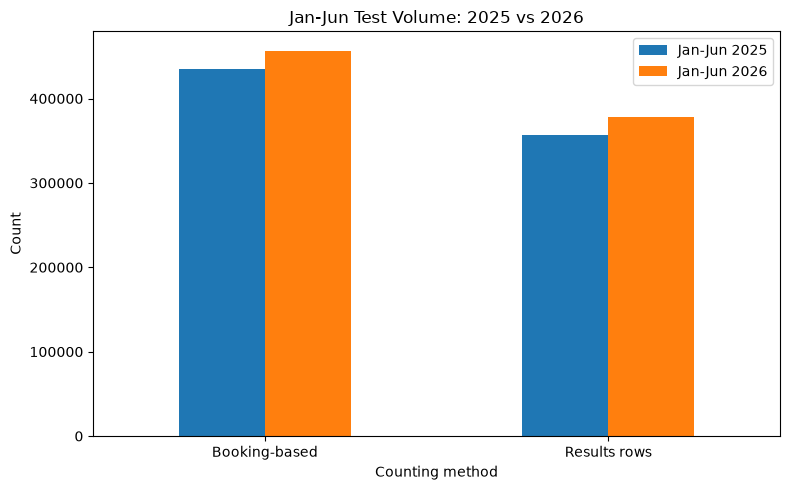

In [89]:
import matplotlib.pyplot as plt

plot = OUTPUT_ROOT / "graphs"
plot.mkdir(parents=True, exist_ok=True)


volume_comparison = pd.DataFrame({
    "metric": ["Booking-based", "Results rows"],
    "Jan-Jun 2025": [tests_25, res_tests_25],
    "Jan-Jun 2026": [tests_26, res_tests_26]
})

ax = volume_comparison.set_index("metric")[["Jan-Jun 2025", "Jan-Jun 2026"]].plot(
    kind="bar", figsize=(8, 5)
)
ax.set_title("Jan-Jun Test Volume: 2025 vs 2026")
ax.set_xlabel("Counting method")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(plot / "01_h1_test_volume_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

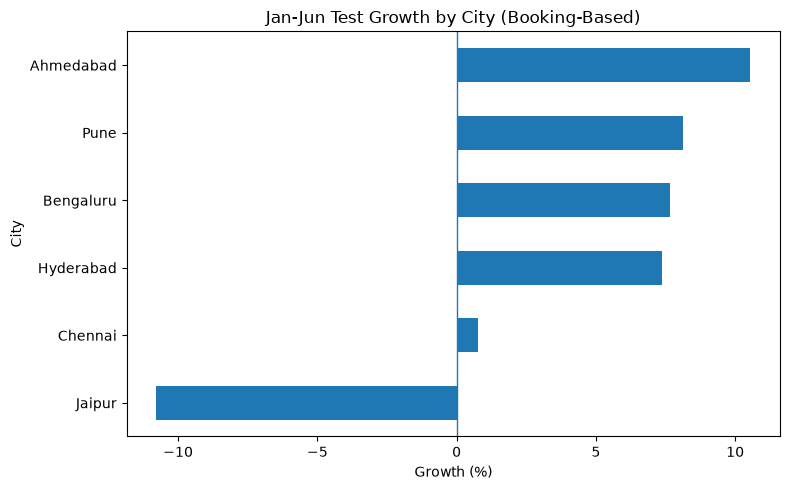

In [90]:

city_plot = city_change.sort_values("growth_pct").copy()

ax = city_plot.plot(
    x="city", y="growth_pct", kind="barh", legend=False, figsize=(8, 5)
)
ax.set_title("Jan-Jun Test Growth by City (Booking-Based)")
ax.set_xlabel("Growth (%)")
ax.set_ylabel("City")
ax.axvline(0, linewidth=1)
plt.tight_layout()
plt.savefig(plot / "02_city_test_growth.png", dpi=150, bbox_inches="tight")
plt.show()

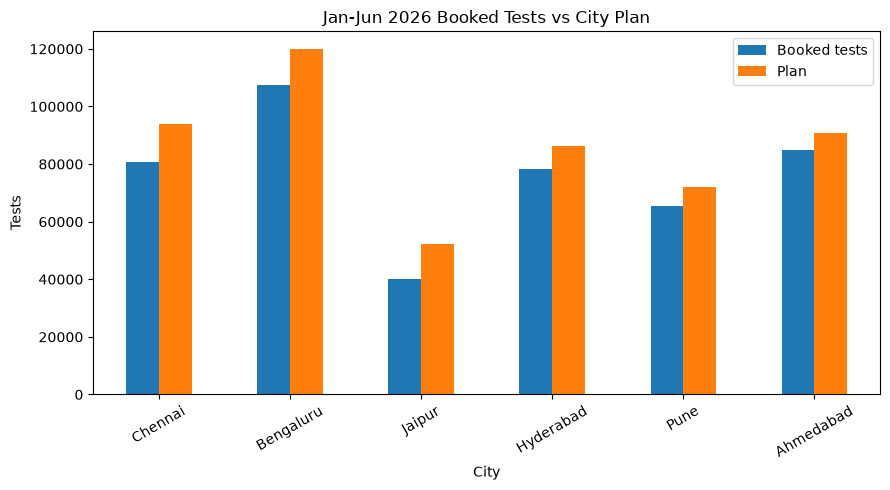

In [60]:

city_plan_plot = city_booking_plan.sort_values("shortfall", ascending=False).copy()

ax = city_plan_plot.set_index("city")[["booked_tests_h1", "city_target_h1"]].plot(
    kind="bar", figsize=(9, 5)
)
ax.set_title("Jan-Jun 2026 Booked Tests vs City Plan")
ax.set_xlabel("City")
ax.set_ylabel("Tests")
ax.legend(["Booked tests", "Plan"])
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(plot / "03_city_booked_vs_plan.png", dpi=150, bbox_inches="tight")
plt.show()


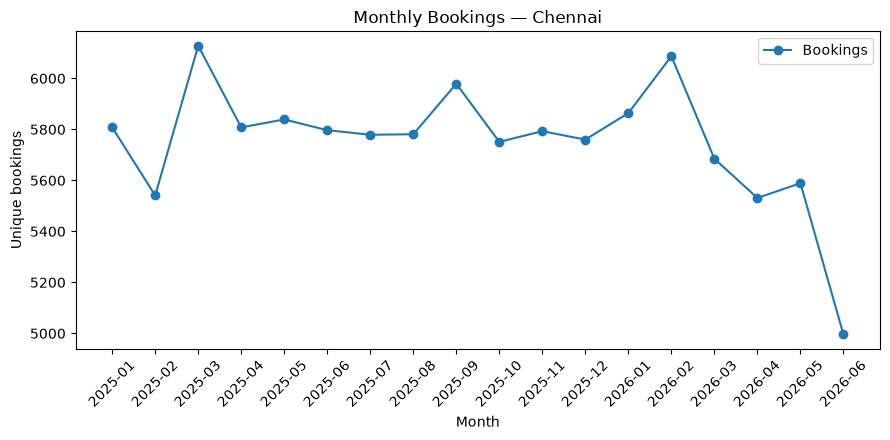

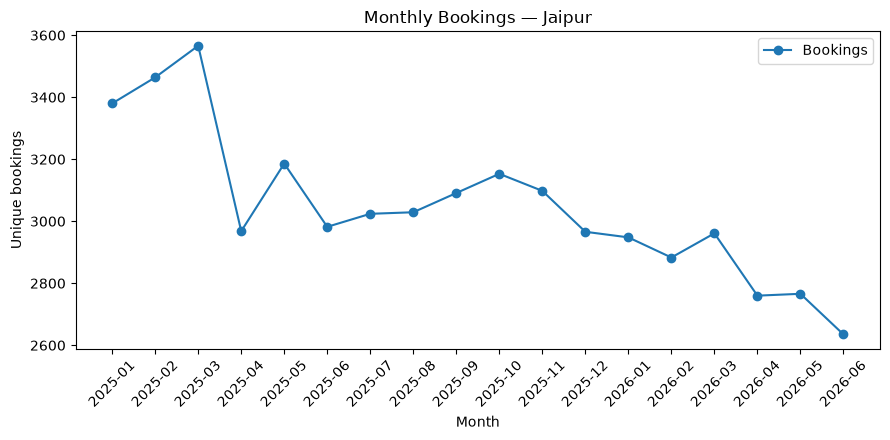

In [91]:

for city_name in CITIES_TO_INVESTIGATE:
    city_month_data = monthly.loc[monthly["city"] == city_name].sort_values("month")
    plt.figure(figsize=(9, 4.5))
    plt.plot(city_month_data["month"], city_month_data["bookings"], marker="o", label="Bookings")
    plt.title("Monthly Bookings — " + city_name)
    plt.xlabel("Month")
    plt.ylabel("Unique bookings")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    safe_city_name = city_name.lower().replace(" ", "_")
    plt.savefig(plot / ("04_monthly_bookings_" + safe_city_name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
